# Model Selection with Decision Trees

**Companion notebook for the BIP ML4DS lecture.** We use a decision tree to make the selection problem concrete, then follow the same validation logic used to compare model configurations.

> **Dataset note:** This notebook uses scikit-learn's built-in Breast Cancer Wisconsin diagnostic dataset as a generic binary-classification example. It is not the steel-plate anomaly-detection project data, and its computed scores are not the illustrative values in the slides.

## Learning goals

- Separate training, validation, and test roles.
- Compare tree-depth configurations using balanced accuracy.
- Use cross-validation within development data.
- Refit the selected configuration on all development data and evaluate once on the reserved test set.
- Recognize how test feedback and data leakage can bias evaluation.

Run the notebook from top to bottom. The test set is not used until the final evaluation section.

## 1. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay

RANDOM_STATE = 42


In [2]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

print(f"Observations: {len(X)}")
print(f"Features: {X.shape[1]}")
print("Target classes:", dict(enumerate(dataset.target_names)))

display(y.value_counts(normalize=True).rename("proportion").to_frame())

Observations: 569
Features: 30
Target classes: {0: 'malignant', 1: 'benign'}


,proportion
target,
1,0.627417
0,0.372583


The target classes are imbalanced, so we will use **balanced accuracy** as the comparison metric. It is the average of recall across classes. The metric is fixed before comparing candidates.

## 2. Reserve the test set; create one validation split

First, hold out a test set. We will not inspect it while choosing a configuration. Split the remaining **development data** into training and validation sets for a simple hold-out comparison.

In [3]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE
)

sizes = pd.Series({
    "training": len(X_train),
    "validation": len(X_val),
    "reserved test": len(X_test),
})
display(sizes.to_frame("number of observations"))

,number of observations
training,341
validation,114
reserved test,114


This gives approximately 60% training, 20% validation, and 20% test data. The validation set is part of development data; the test set remains reserved for the final assessment.

## 3. Hold-out selection: compare tree depths

A candidate here is a decision tree with a particular `max_depth`. We fit each candidate on training data, then compare its training and validation balanced accuracy. Training performance alone does not determine the choice.

In [4]:
candidate_depths = [2, 5, None]

def depth_name(depth):
    return "Unrestricted" if depth is None else str(depth)

holdout_rows = []
for depth in candidate_depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    holdout_rows.append({
        "maximum depth": depth_name(depth),
        "training balanced accuracy": balanced_accuracy_score(y_train, model.predict(X_train)),
        "validation balanced accuracy": balanced_accuracy_score(y_val, model.predict(X_val)),
        "number of leaves": model.get_n_leaves(),
    })

holdout_results = pd.DataFrame(holdout_rows)
display(holdout_results.round(3))

,maximum depth,training balanced accuracy,validation balanced accuracy,number of leaves
0,2,0.963,0.939,4
1,5,0.998,0.960,14
2,Unrestricted,1.000,0.960,15


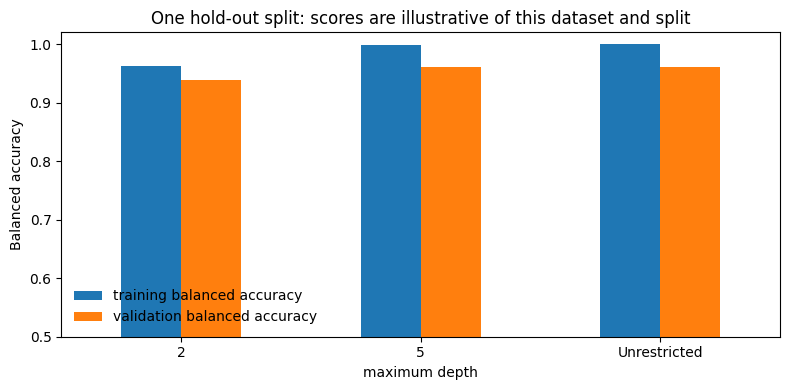

In [5]:
ax = holdout_results.set_index("maximum depth")[[
    "training balanced accuracy", "validation balanced accuracy"
]].plot(kind="bar", figsize=(8, 4), ylim=(0.5, 1.02), rot=0)
ax.set_ylabel("Balanced accuracy")
ax.set_title("One hold-out split: scores are illustrative of this dataset and split")
ax.legend(loc="lower left", frameon=False)
plt.tight_layout()

**Interpretation prompt:** Which depth would you choose using the validation score? Does the highest training score give the same answer?

The result depends on this particular validation split. Next, we use cross-validation as an alternative way to compare candidates within the same development data. The test set remains untouched.

## 4. Cross-validation within development data

In 3-fold cross-validation, each candidate is fitted three times. Each run holds out one development fold for validation and uses the other folds for training. We average the fold scores for each candidate. The same folds are used to compare all depths.

In scikit-learn, the returned key is named `test_score`; here it is the score on a held-out **validation fold**, not the reserved test set. The code below gives it the clearer local name `fold_validation_scores`.


In [6]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_records = []

for depth in candidate_depths:
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    result = cross_validate(
        candidate,
        X_dev,
        y_dev,
        cv=cv,
        scoring="balanced_accuracy",
        return_train_score=True,
        return_estimator=True,
    )
    fold_train_scores = result["train_score"]
    fold_validation_scores = result["test_score"]  # held-out CV fold, not the reserved test set
    cv_records.append({
        "maximum depth": depth_name(depth),
        "mean training score": fold_train_scores.mean(),
        "mean validation score": fold_validation_scores.mean(),
        "validation score SD": fold_validation_scores.std(ddof=1),
        "mean number of leaves": np.mean([tree.get_n_leaves() for tree in result["estimator"]]),
    })

cv_summary = pd.DataFrame(cv_records)
display(cv_summary.round(3))

,maximum depth,mean training score,mean validation score,validation score SD,mean number of leaves
0,2,0.962,0.913,0.019,4.000
1,5,0.993,0.922,0.013,10.667
2,Unrestricted,1.000,0.914,0.011,13.000


**Mean number of leaves** is the average number of terminal nodes in the fold-specific trees. It describes model size, not predictive performance. The standard deviation shown here summarizes variation across these folds; it is not automatically a confidence interval for generalization performance.

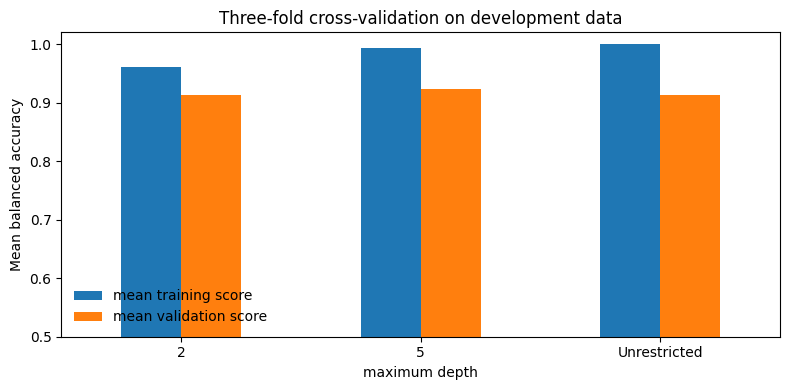

In [7]:
ax = cv_summary.set_index("maximum depth")[[
    "mean training score", "mean validation score"
]].plot(kind="bar", figsize=(8, 4), ylim=(0.5, 1.02), rot=0)
ax.set_ylabel("Mean balanced accuracy")
ax.set_title("Three-fold cross-validation on development data")
ax.legend(loc="lower left", frameon=False)
plt.tight_layout()

### Select a configuration

We select the candidate with the highest **mean validation balanced accuracy**. The test set does not appear in this selection step.

In [8]:
best_index = int(cv_summary["mean validation score"].to_numpy().argmax())
best_depth = candidate_depths[best_index]
best_cv_score = cv_summary.loc[best_index, "mean validation score"]

print("Selected maximum depth:", depth_name(best_depth))
print(f"Mean cross-validation balanced accuracy: {best_cv_score:.3f}")

Selected maximum depth: 5
Mean cross-validation balanced accuracy: 0.922


### Optional explorations — do these before the final test evaluation


- Add more values to `candidate_depths` and compare how mean validation score and mean number of leaves change.
- Change the number of CV folds. Does the selected depth change? How do the fold scores vary?
- Try a different metric only after stating why it fits the task. Keep the metric fixed while comparing candidates.
- Sketch a candidate set containing multiple algorithms. Use the same folds and scoring rule, while allowing any necessary preprocessing to be specific to each algorithm and fitted within the folds.

If you change the candidate set or metric, use development data to make the new selection. Do not choose among models using repeated test scores.

## 5. Refit and evaluate once on the reserved test set

The fold-specific trees helped compare configurations; they are not automatically the final model. Once the configuration is fixed, fit a new tree using all development data, then evaluate it once on the untouched test set.

In [9]:
final_model = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE)
final_model.fit(X_dev, y_dev)

test_predictions = final_model.predict(X_test)
final_test_score = balanced_accuracy_score(y_test, test_predictions)

print("Selected maximum depth:", depth_name(best_depth))
print(f"Mean validation balanced accuracy: {best_cv_score:.3f}")
print(f"Reserved test balanced accuracy: {final_test_score:.3f}")

Selected maximum depth: 5
Mean validation balanced accuracy: 0.922
Reserved test balanced accuracy: 0.923


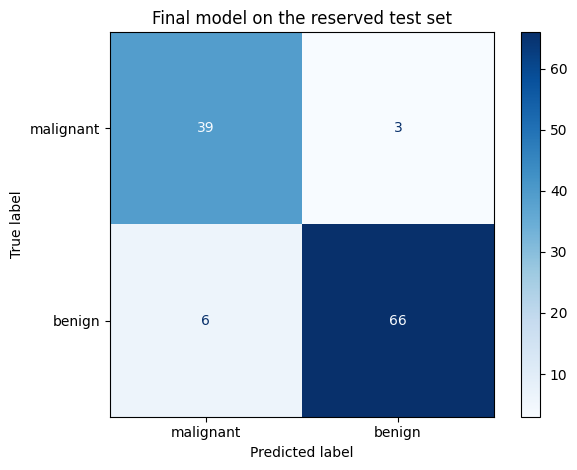

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=dataset.target_names,
    cmap="Blues",
    values_format="d",
)
plt.title("Final model on the reserved test set")
plt.tight_layout()

Report the selected configuration, the selection procedure, the metric, and the test result separately from the winning cross-validation score. The test score may be higher or lower than the validation score.

## 6. What would invalidate the final test estimate?

If we inspect the test score, change `max_depth`, preprocessing, or a decision threshold, and then report the best test score, the test data have influenced model selection. They are now providing development feedback, and the selected score may be overly optimistic. A fresh independent evaluation would be needed for the revised procedure.

Likewise, learned preprocessing must be fitted inside each training fold. In scikit-learn, a `Pipeline` can keep transformations inside the cross-validation loop. The split must also reflect the intended use: for example, related images or observations from the same session should not be scattered across training and validation when the goal is to generalize to a new session.

## 7. Check your understanding

1. Why can the unrestricted tree have perfect training accuracy and still lose to a shallower tree on validation data?
2. Which data are used to fit the final tree after the configuration is selected?
3. Why is the test score not used to select `max_depth`?
4. If two algorithms are candidates, what should remain consistent in their comparison?
5. For the steel-plate project, what kind of split would match the intended deployment setting: a random image split, a held-out capture session, or something else? What metadata would you need to decide?